# Code tutorial connectomics I - Computational Neuroscience

This tutorial recreates the Rich Club analysis from Towlson et al., 2013, Journal of Neuroscience

# Imports and installation

In [6]:
#!git clone https://github.com/ChristianPritz/unito_computational_neuroscience
#%cd unito_connectomics_i
#%pip install -U navis plotly ipywidgets jupyterlab_widgets jupyterlab nbformat networkx neuprint-python matplotlib pandas numpy seaborn
import os
import sys
import pandas as pd
import networkx as nx
from networkx.algorithms import community
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
sys.path.append(os.getcwd()+'/code')
from connectomics_functions import *

## Exploring basic concepts in graph theory for connectomics

In this section, we will explore some fundamental concepts of graph theory applied to connectomics.

We will start by loading an adjacency matrix, visualising the corresponding graph, and examining some basic network statistics:

- **In-degree and out-degree:** quantify the number of incoming and outgoing connections for each neuron.
- **Shortest path length:** measures the minimum number of connections needed to travel from one neuron to another.
- **Clustering coefficient:** measures how strongly interconnected a neuron's neighbours are. We can calculate it for each neuron and then compute the average across the network:

$$
C_i = \frac{2E_i}{k_i(k_i-1)}, \qquad
C = \frac{1}{N}\sum_{i=1}^{N} C_i
$$

- **Small-world coefficient:** compares the clustering coefficient and average shortest path length of the observed network with those of an equivalent random network:

$$
\sigma = \frac{C/C_{\mathrm{rand}}}{L/L_{\mathrm{rand}}}
$$

#### Abbreviations and notation

- $C_i$: clustering coefficient of neuron $i$.
- $C$: average clustering coefficient of the network.
- $E_i$: number of connections between the neighbours of neuron $i$.
- $k_i$: degree of neuron $i$.
- $N$: total number of neurons in the network.
- $L$: average shortest path length of the observed network.
- $C_{\mathrm{rand}}$: average clustering coefficient of random networks.
- $L_{\mathrm{rand}}$: average shortest path length of random networks.
- $\sigma$: small-world coefficient.

#### Let's load an adjacency matrix of a small network

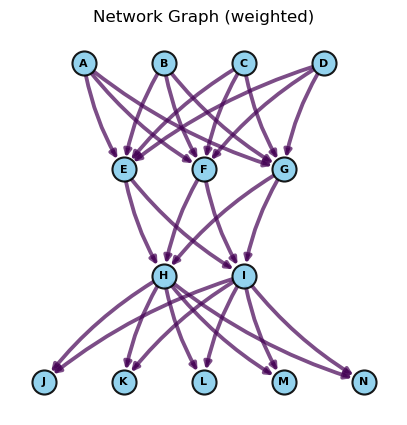

/home/wormulon/models/unito_computational_neuroscience/connectomics_i/code/connectomics_functions.py:273: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


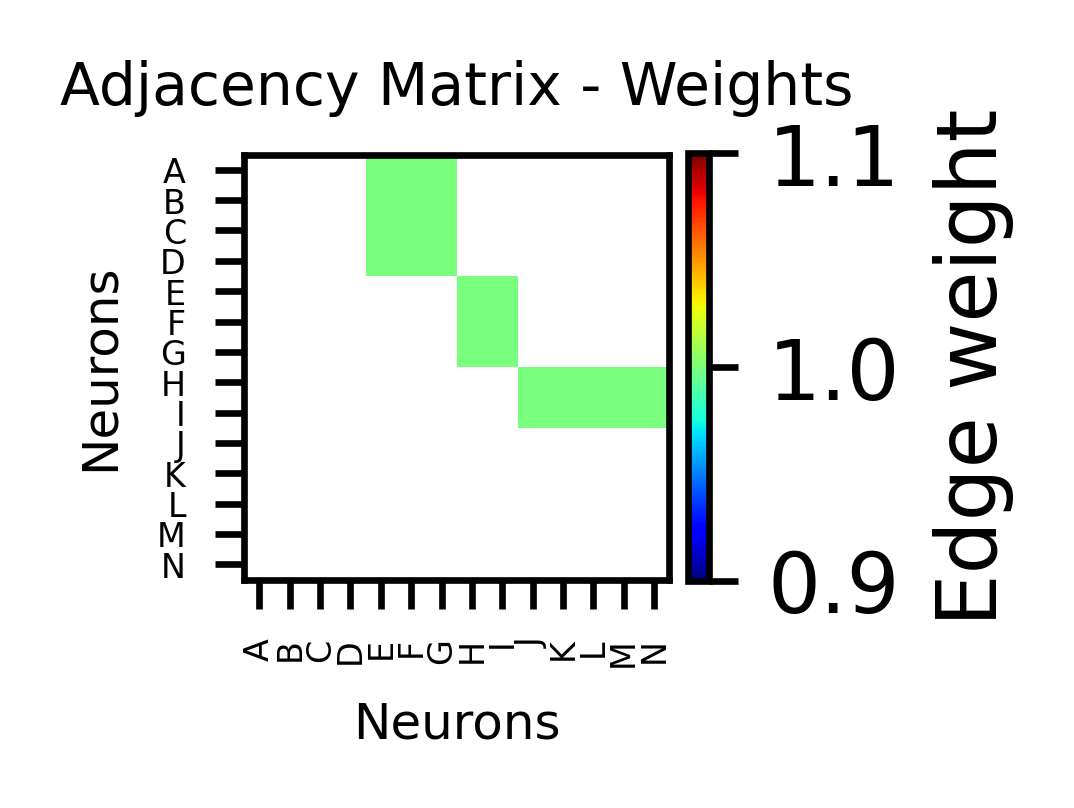

NETWORK STATISTICS
Number of neurons: 14
Total number of connections: 28
--------------------------------------------------------------
DEGREE STATISTICS
Average in-degree: 2.0
Average out-degree: 2.0
--------------------------------------------------------------
PATH LENGTH AND REACHABILITY
Average directed shortest path length: 1.8873239436619718
Reachability: 39.01 %
--------------------------------------------------------------
CLUSTERING AND SMALL-WORLDNESS
Average clustering coefficient: 0.0
Random network clustering: 0.308994708994709
Real network path length (largest component): 1.9120879120879122
Random network path length: 1.901098901098901
Small-world coefficient (sigma): 0.0


In [14]:
# loading the adjacency matrix from a csv file in the data folder
A_machine, nodes = load_adjacency_matrix(os.getcwd()+"/data/testConn.csv")
#instantiating the the graph and renaming the neurons 
G_machine = nx.from_numpy_array(A_machine, create_using=nx.DiGraph)
G_machine = nx.relabel_nodes(G_machine, dict(enumerate(nodes)))#

# this variable sorts the position of the neurons in the graph
positions = {"A": [0,0],
             "B": [1,0],
             "C": [2,0],
             "D": [3,0],
             "E": [0.5,-1],
             "F": [1.5,-1],
             "G": [2.5,-1],
             "H": [1,-2],
             "I": [2,-2],
             "J": [-0.5,-3],
             "K": [0.5,-3],
             "L": [1.5,-3],
             "M": [2.5,-3],
             "N": [3.5,-3],}

#Let us plot the graph 
plot_network(G_machine,positions=positions)
plot_adjacency_matrix(G_machine,sort_nodes=False, figsize=(1,1))
stats_machine = basic_stats(G_machine)





### This doesn't look like a graph from biological network. 
Let's rework the graph  so that the information can flow bi-directionally. Try to edit it until the reachability is 100% and graph is fully connected. 

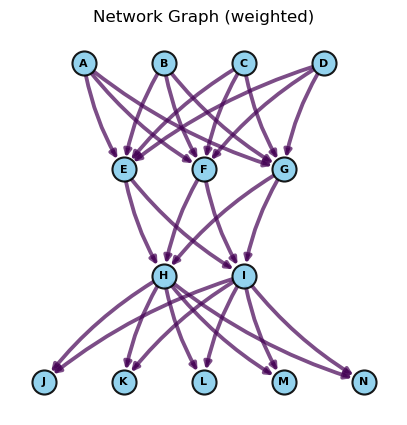

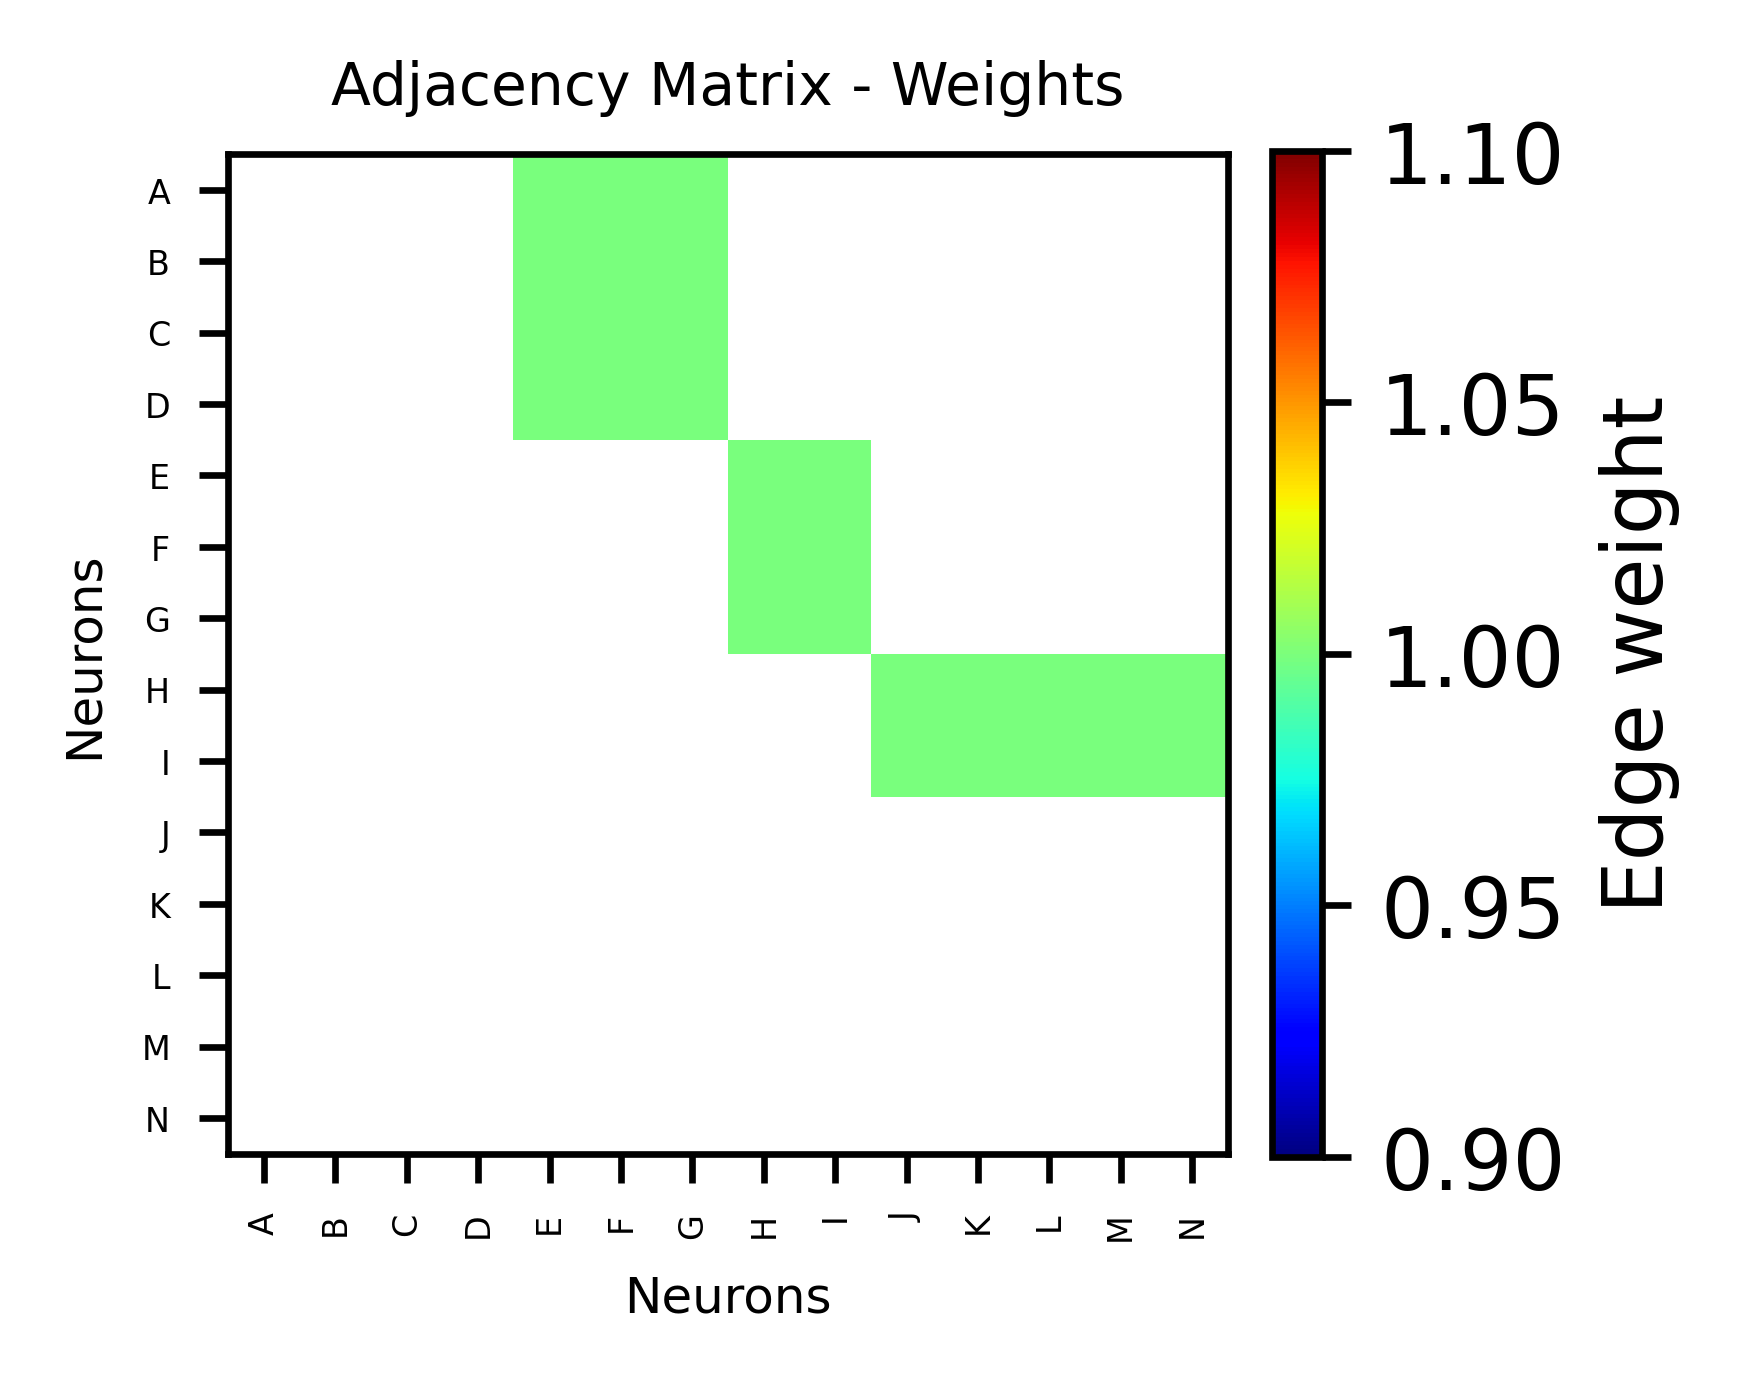

NETWORK STATISTICS
Number of neurons: 14
Total number of connections: 28
--------------------------------------------------------------
DEGREE STATISTICS
Average in-degree: 2.0
Average out-degree: 2.0
--------------------------------------------------------------
PATH LENGTH AND REACHABILITY
Average directed shortest path length: 1.8873239436619718
Reachability: 39.01 %
--------------------------------------------------------------
CLUSTERING AND SMALL-WORLDNESS
Average clustering coefficient: 0.0
Random network clustering: 0.27613945578231297
Real network path length (largest component): 1.9120879120879122
Random network path length: 1.878021978021978
Small-world coefficient (sigma): 0.0


In [8]:

A_edit = np.array([[0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1.],
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1.],
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])


G_edit = nx.from_numpy_array(A_edit, create_using=nx.DiGraph)
G_edit = nx.relabel_nodes(G_edit, dict(enumerate(nodes)))
plot_network(G_edit,positions=positions)
plot_adjacency_matrix(G_edit,sort_nodes=False, figsize=(3,3))
stats_edit = basic_stats(G_edit)

# Teacher cell

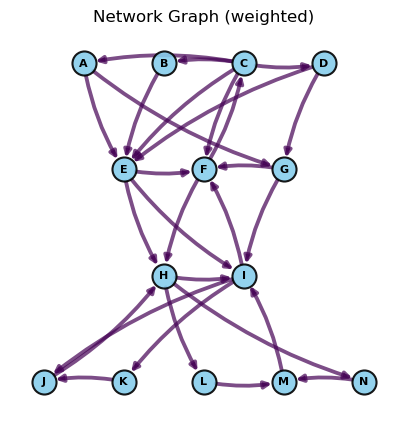

/home/wormulon/models/unito_computational_neuroscience/connectomics_i/code/connectomics_functions.py:131: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


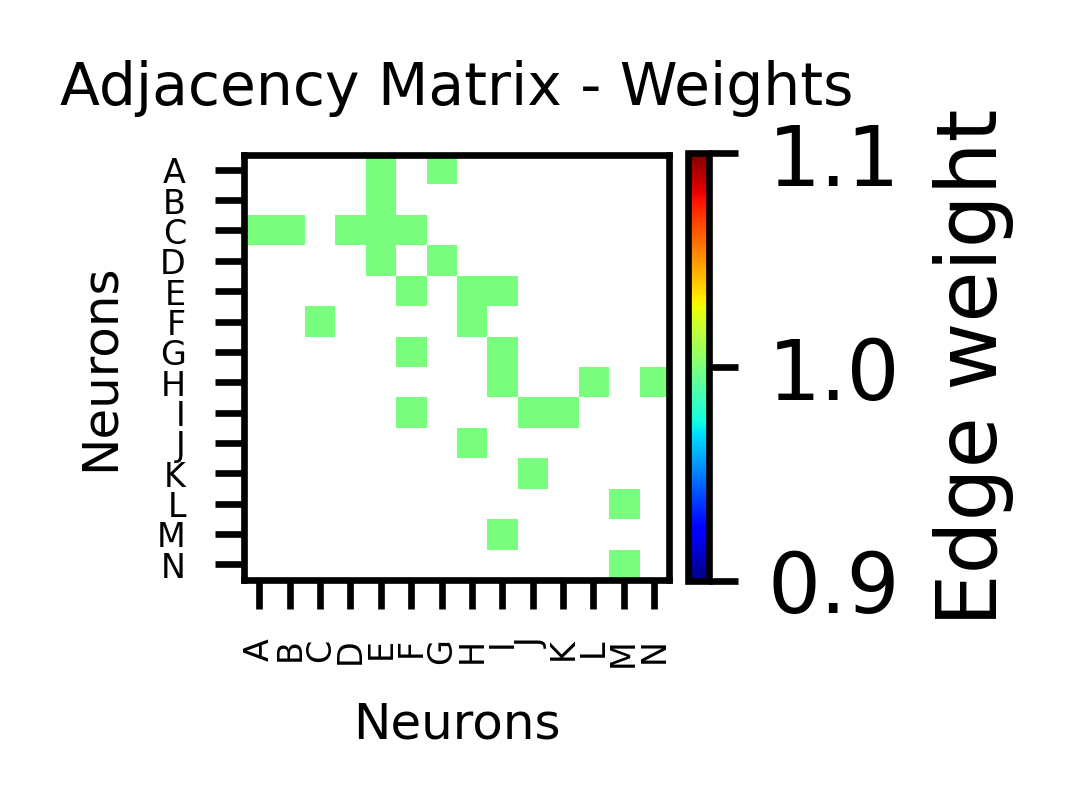

Total number of connections: 28
Average in-degree: 2.0
Average out-degree: 2.0
------------------------------------------------------------------
Average min. path length: 2.9615384615384617
Reachability 100.0 %


In [4]:
# loading the adjacency matrix from a csv file in the data folder
A_bio, nodes = load_adjacency_matrix(os.getcwd()+"/data/testConn2.csv")
#instantiating the the graph and renaming the neurons 
G_bio = nx.from_numpy_array(A_bio, create_using=nx.DiGraph)
G_bio = nx.relabel_nodes(G_bio, dict(enumerate(nodes)))

#Let us plot the graph 
plot_network(G_bio,positions=positions)
plot_adjacency_matrix(G_bio,sort_nodes=False, figsize=(1,1))
stats_bio = basic_stats(G_bio)

# Let's load the C.elegans connectome

In [9]:
# ======== LOAD DATA ==========================================================
edge_list_path = "./data/NeuronConnect.csv"
raw_data = pd.read_csv(edge_list_path)
raw_data = raw_data.rename(columns={'Nbr': 'weight'})

raw_data = raw_data.drop(np.where(raw_data.Type == "NMJ")[0])

# instantiating a directed graph
G_dir = nx.from_pandas_edgelist(
    raw_data,
    source='Neuron 1',
    target='Neuron 2',
    edge_attr='weight',
    create_using=nx.DiGraph()
)

#the edges are stored in adjacency dict
print('#############################################################')
print("The adjacency matrix has", str(len(G_dir._adj)), "entries")
print("Individual edges per neurons in this dict look like the \n this (AWCR as example):")
for nbr, datadict in G_dir.adj['AWCR'].items():
    print(nbr,datadict)


#nodes are stored in a the nodes property. 
print('#############################################################')
nodes = list(G_dir.nodes)[:10]
print("Nodes are stored in the 'node' property")
print(f"{nodes} ... and many more")

#############################################################
The adjacency matrix has 281 entries
Individual edges per neurons in this dict look like the 
 this (AWCR as example):
ADLR {'weight': 3}
AIAL {'weight': 1}
AIAR {'weight': 1}
AIBR {'weight': 4}
AIYL {'weight': 3}
AIYR {'weight': 6}
ASEL {'weight': 1}
ASER {'weight': 1}
ASGR {'weight': 1}
ASIL {'weight': 1}
ASIR {'weight': 1}
AWCL {'weight': 4}
#############################################################
Nodes are stored in the 'node' property
['ADAR', 'ADAL', 'ADFL', 'ASHL', 'AVDR', 'PVQL', 'ADEL', 'AIAL', 'AIBL', 'AIBR'] ... and many more


### Let us see the adjacency matrix
#### Note that the adjacency matrix is sparse! 

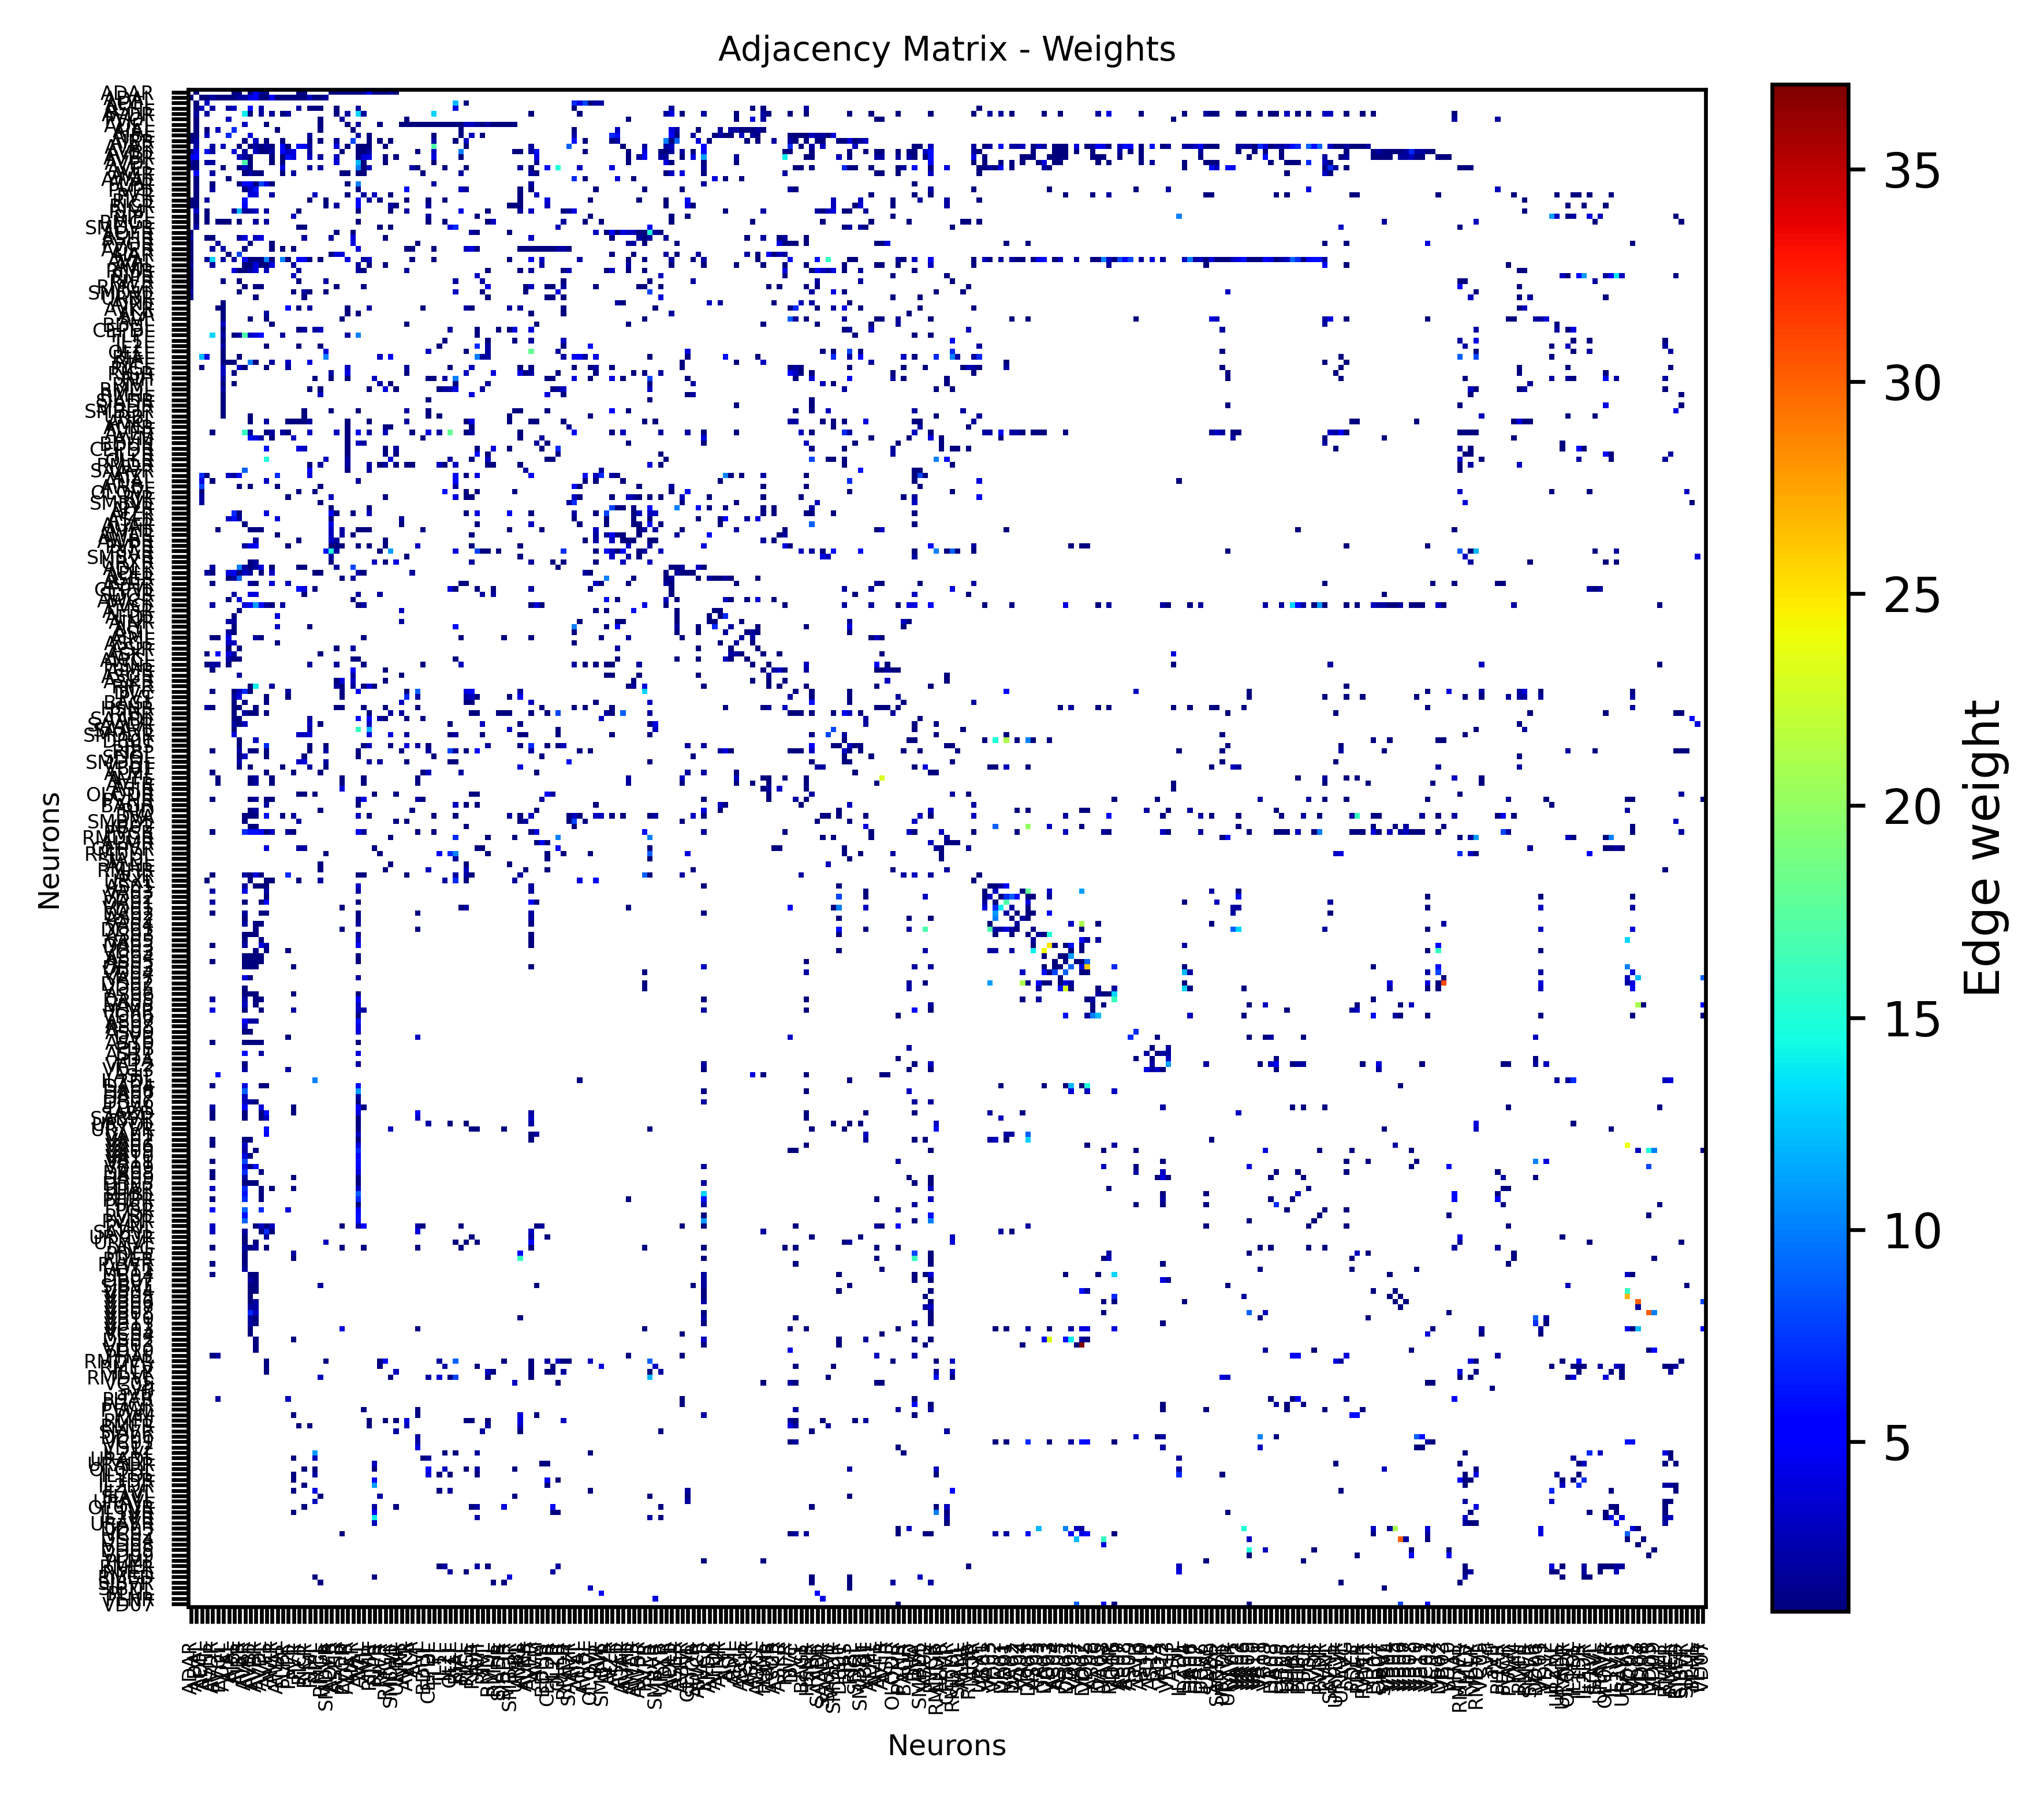

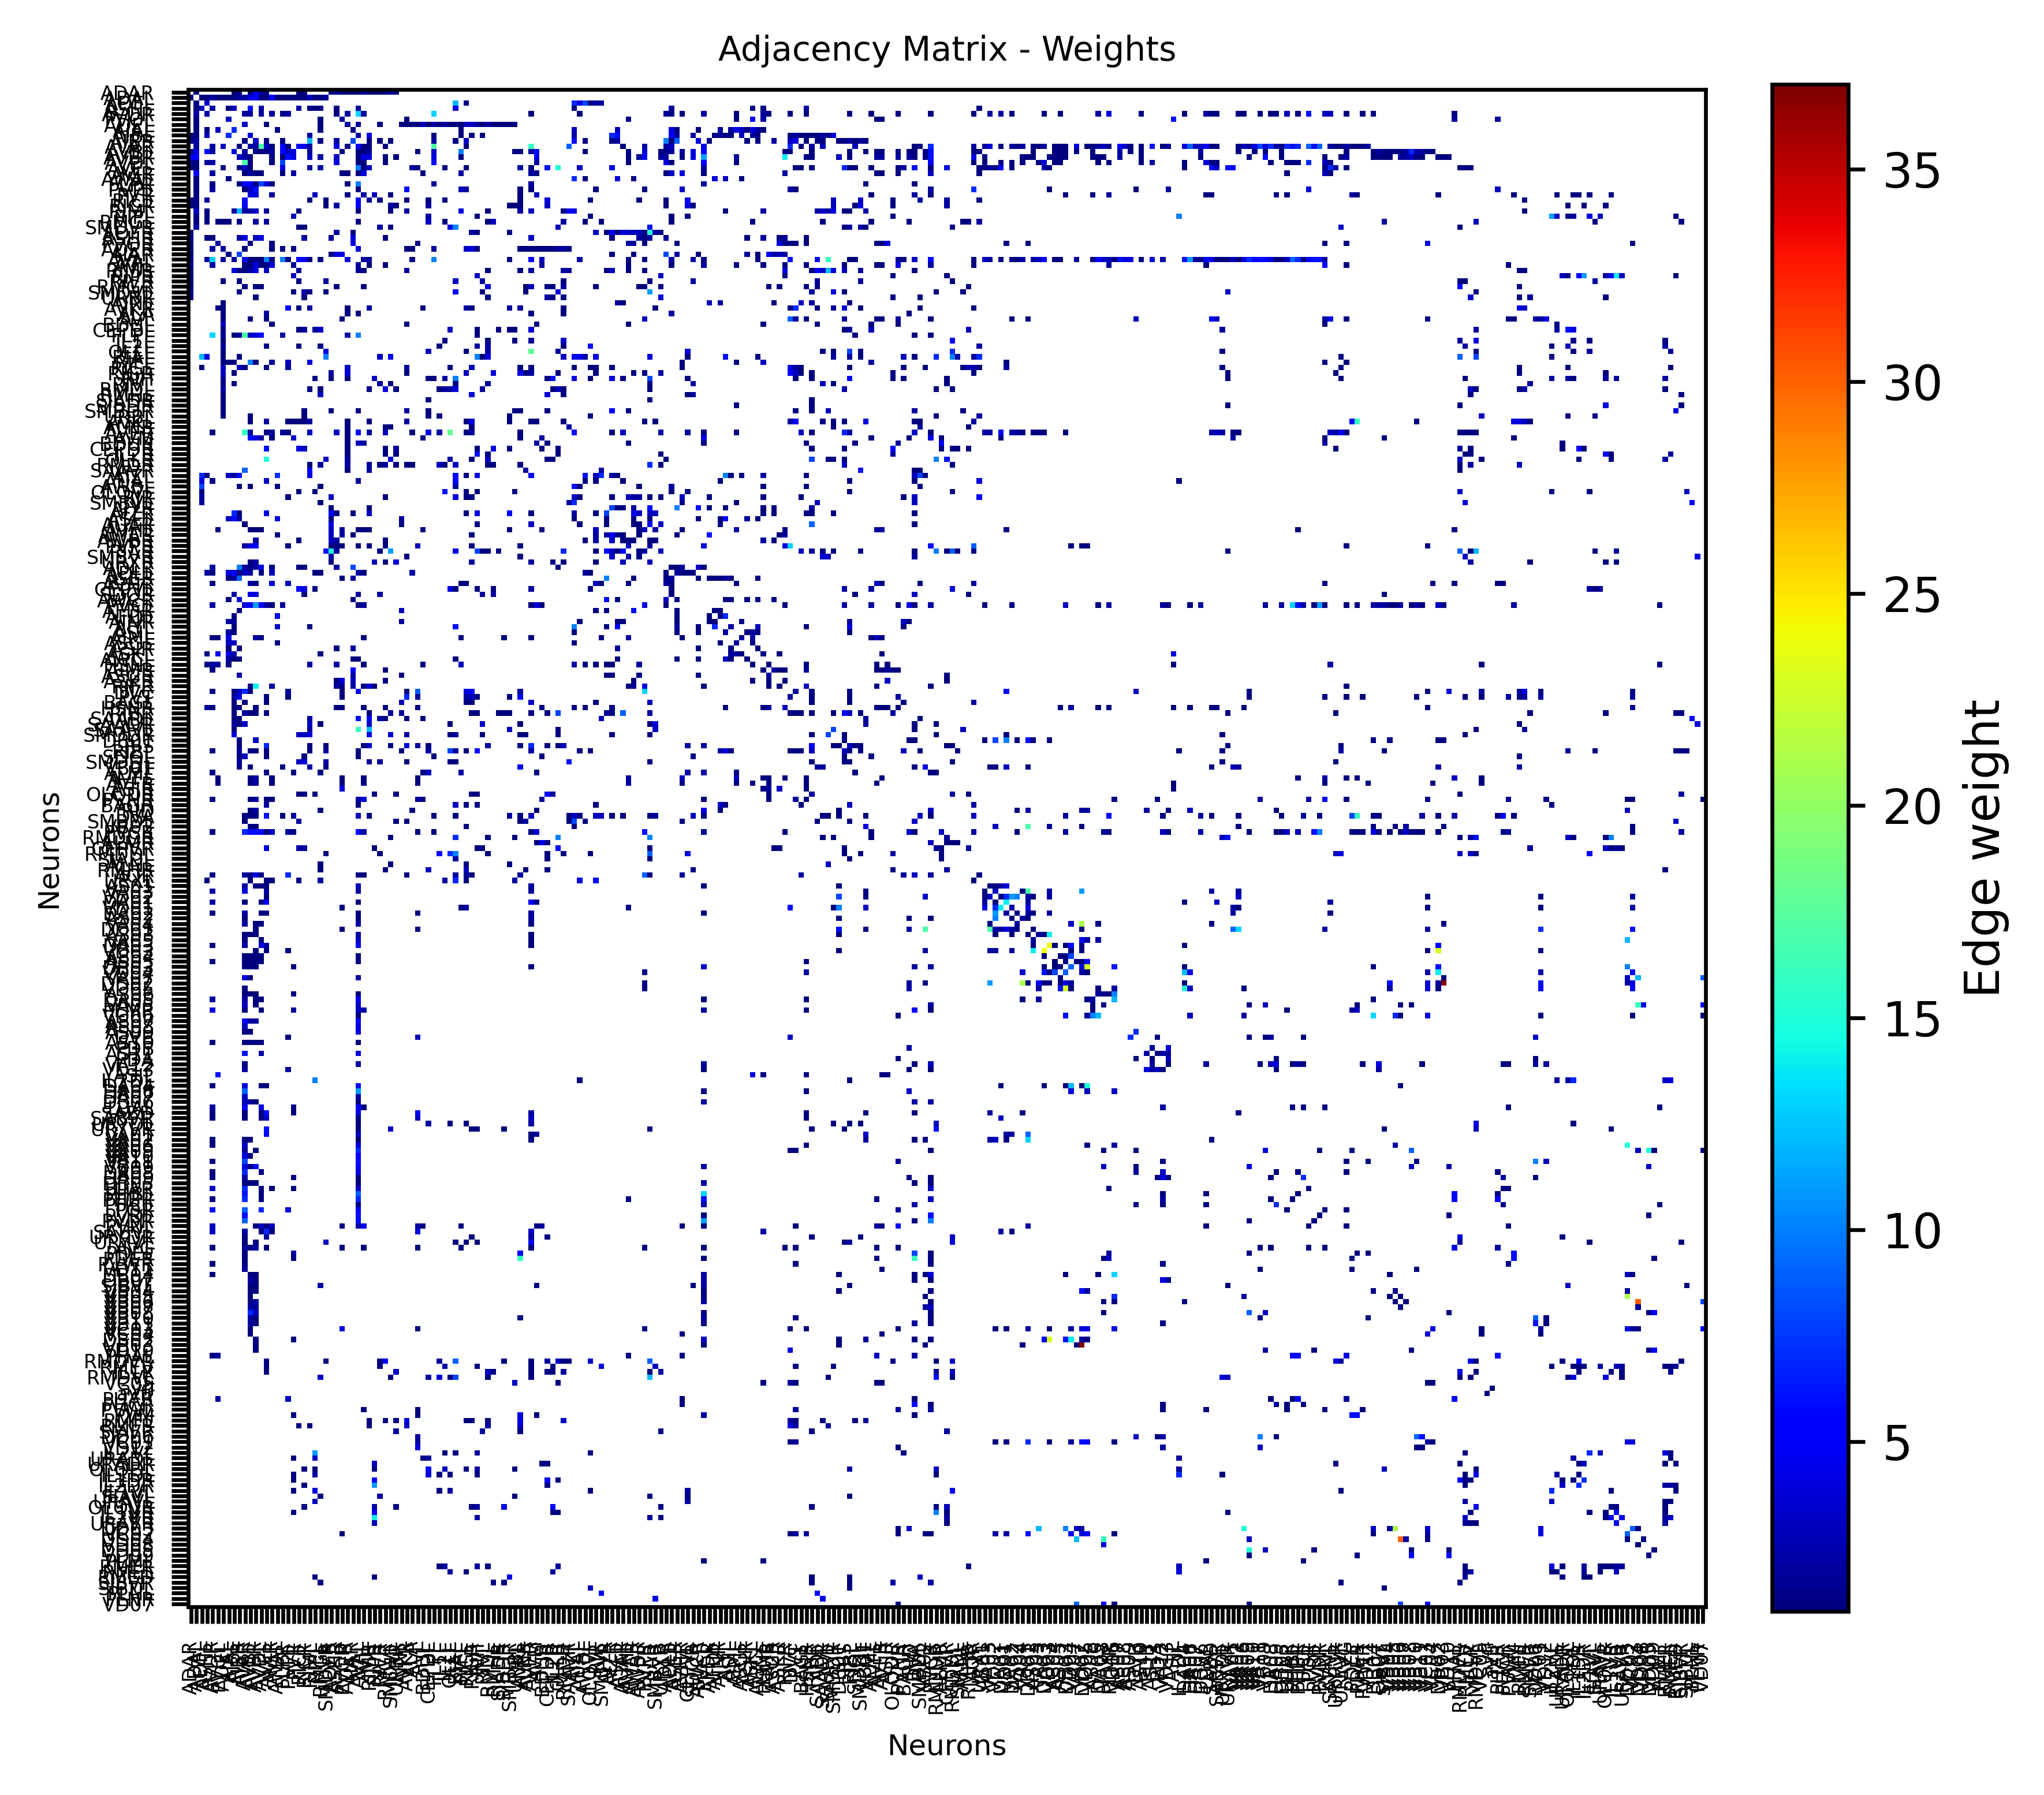

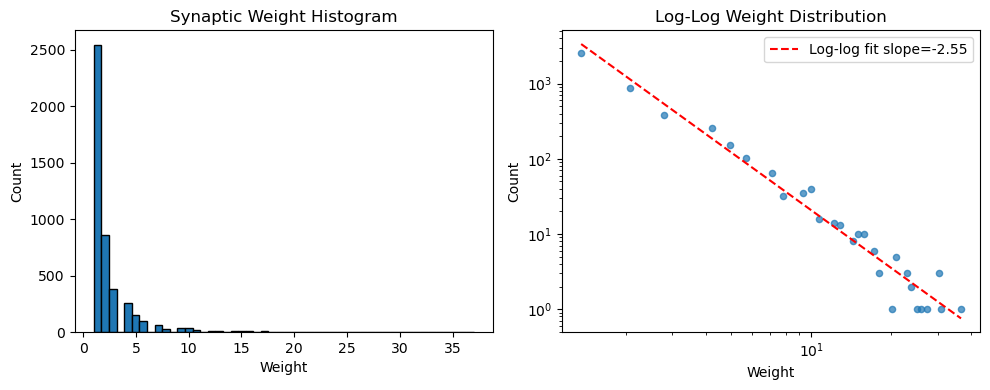

NETWORK STATISTICS
Number of neurons: 281
Total number of connections: 4578
--------------------------------------------------------------
DEGREE STATISTICS
Average in-degree: 16.291814946619215
Average out-degree: 16.291814946619215
--------------------------------------------------------------
PATH LENGTH AND REACHABILITY
Average directed shortest path length: 2.4356071838376545
Reachability: 98.58 %
--------------------------------------------------------------
CLUSTERING AND SMALL-WORLDNESS
Average clustering coefficient: 0.33473446884639313
Random network clustering: 0.05906314718717266
Real network path length (largest component): 2.435625692993992
Random network path length: 2.3001263505324774
Small-world coefficient (sigma): 5.352109590480252


In [10]:
#plotting a adjacency matrix 
plot_adjacency_matrix(G_dir,cmap='jet',sort_nodes=False,figsize=(6,6))

#the undirected graph would look like this: 
G_und = G_dir.to_undirected()
plot_adjacency_matrix(G_und,cmap='jet',sort_nodes=False,figsize=(6,6))

plot_weight_distribution(G_dir, bins=50, fit_powerlaw=True)

stats_elegans = basic_stats(G_dir)




# Let's compute the rich club

We compute the rich club coefficient $\phi$ for all degrees (k) 

$$\phi(k) = \frac{2E_{>k}}{N_{>k}(N_{>k}-1)}$$

we determine if a rich club candidate neuron is signficiant if: $ \phi(real) >  \phi(rand)  + stdev(\phi(rand) ) $
   

Rich-club threshold degree: 41
Number of neurons in rich club: 11
Rich-club neurons: ['AVDR', 'AVAR', 'AVBL', 'AVBR', 'AVDL', 'AVEL', 'AVAL', 'AVER', 'PVCL', 'DVA', 'PVCR']


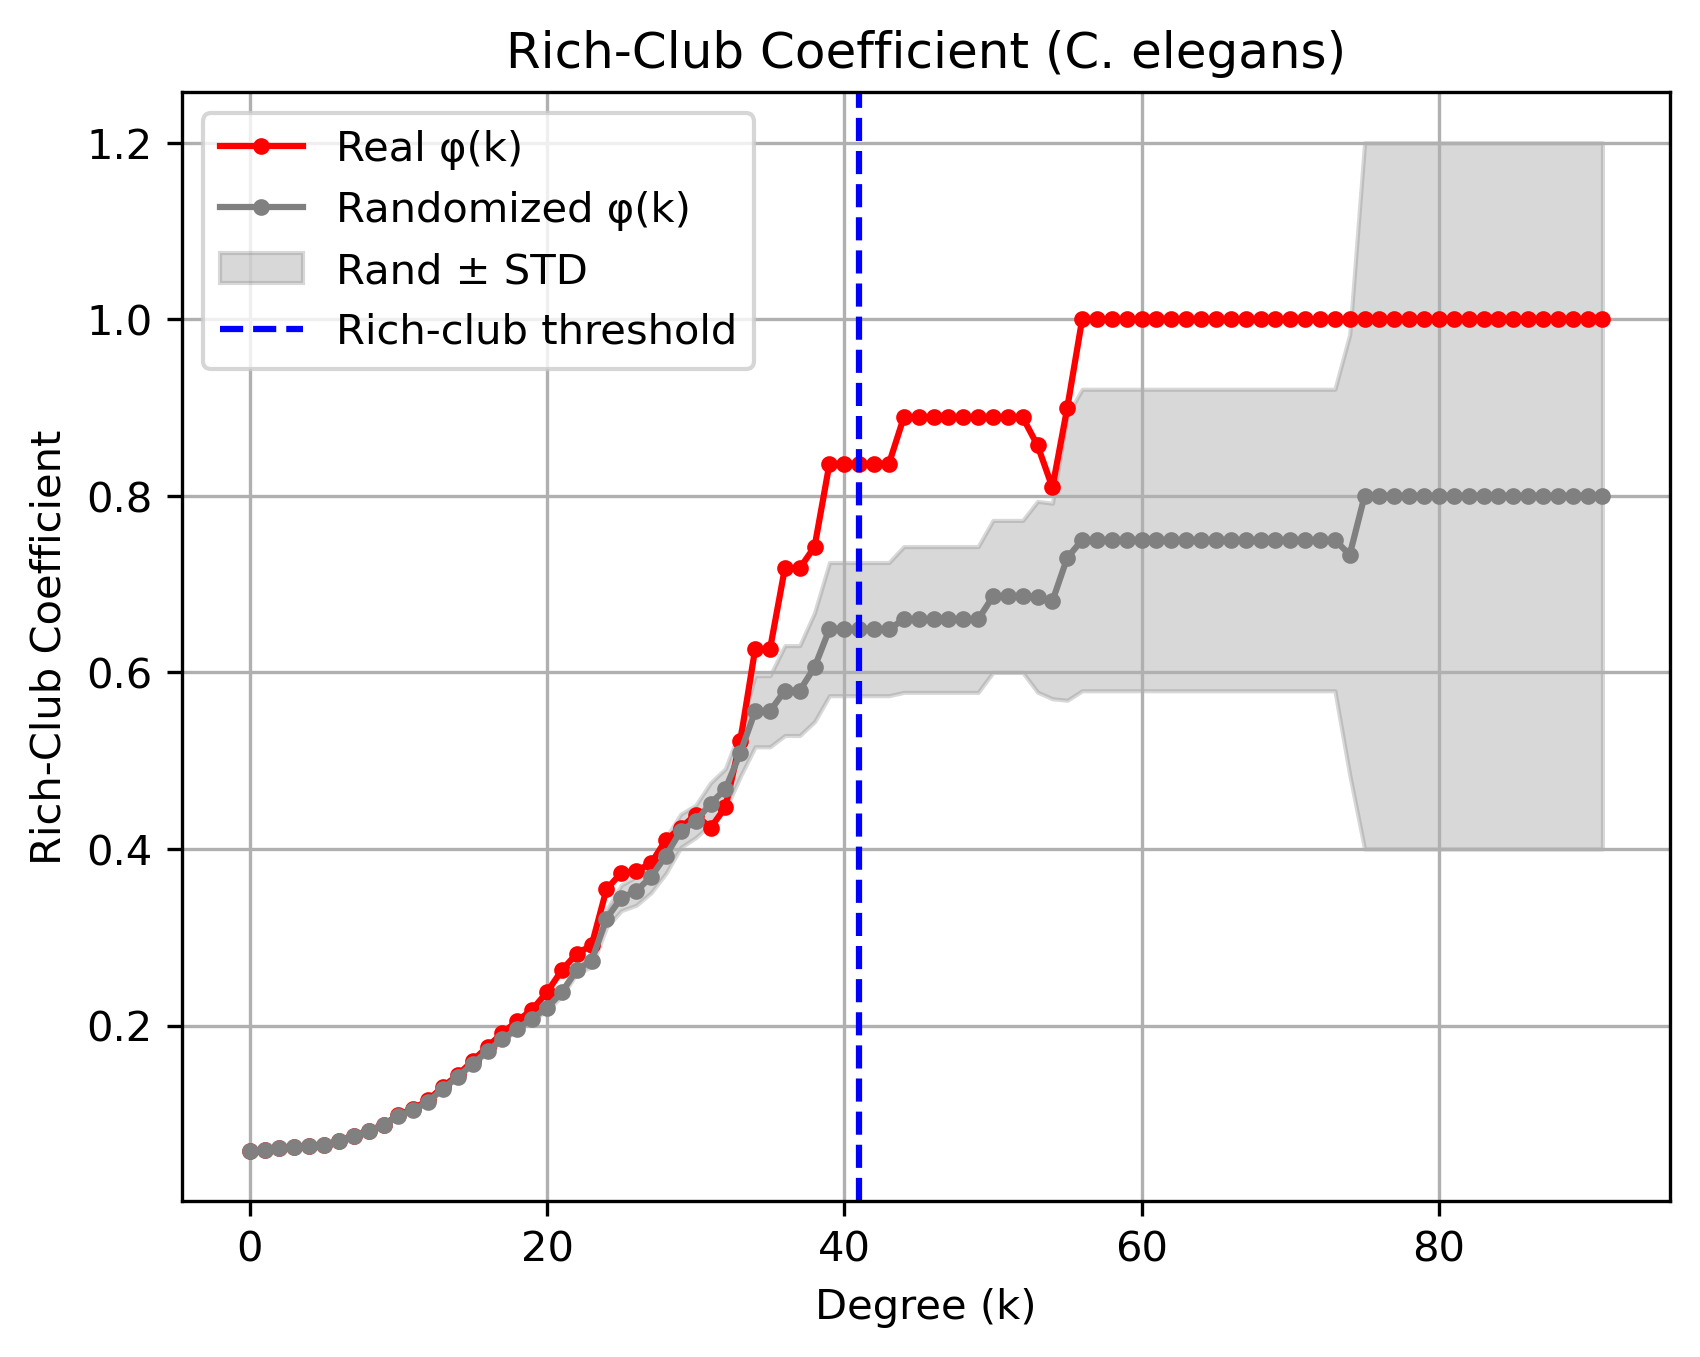

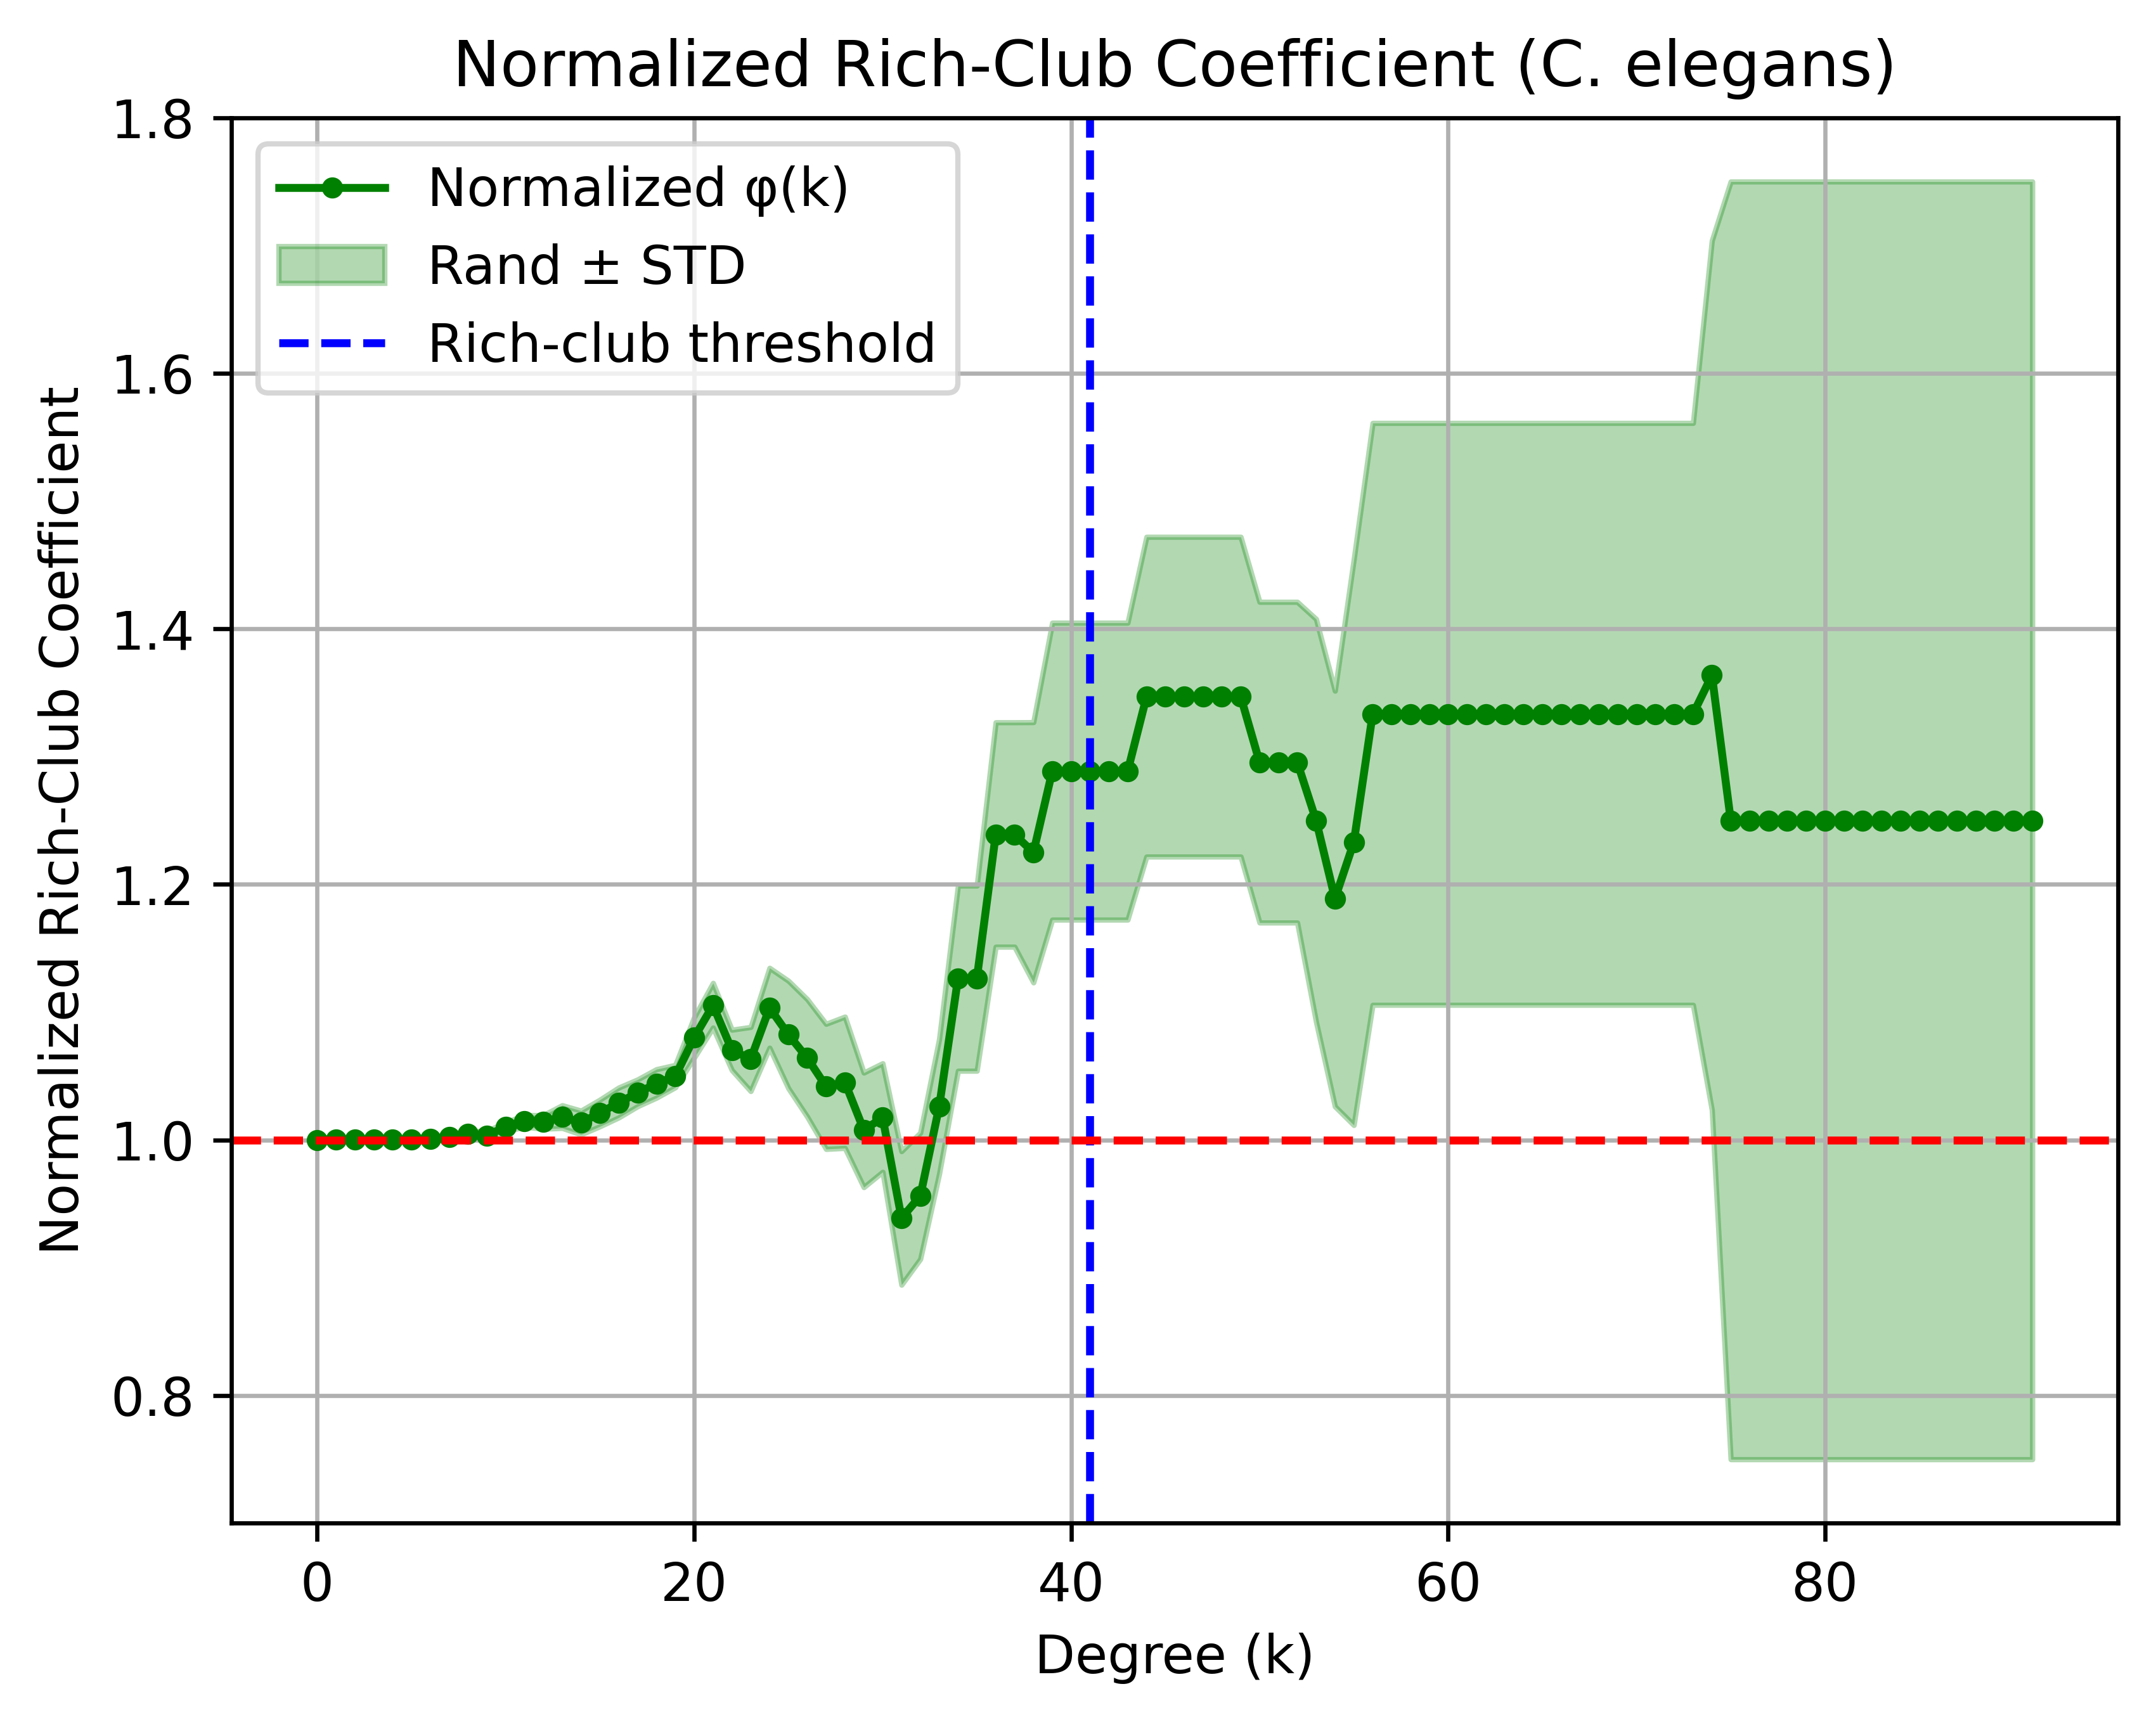

In [11]:
# ======== COMPUTE RICH-CLUB ========
rc_real, rc_rand_avg, rc_rand_std, rc_norm =  rich_club(G_dir, method="config_preserving",n_rand=10)

# Convert to undirected and get degrees
G_und = G_dir.to_undirected()
degrees = dict(G_und.degree())


# ======== DETERMINE RICH-CLUB THRESHOLD ========
k_vals = list(rc_real.keys())
significant_k = [k for k in k_vals if rc_real[k] > rc_rand_avg[k] + rc_rand_std[k]]

if not significant_k:
    print("No significant rich-club degree found")
    k_rich = None
    rich_club_neurons = []
else:
    k_rich = 41 # This is the value from the paper............
    rich_club_neurons = [n for n, d in degrees.items() if d >= k_rich]
    print(f"Rich-club threshold degree: {k_rich}")
    print(f"Number of neurons in rich club: {len(rich_club_neurons)}")
    print("Rich-club neurons:", rich_club_neurons)

plot_rich_club(rc_real,rc_rand_avg,rc_rand_std,rc_norm,k_vals,k_rich)


## Why is the Rich Club at higher degrees not significant?

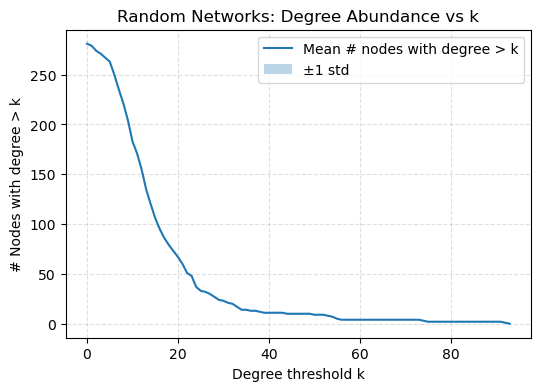

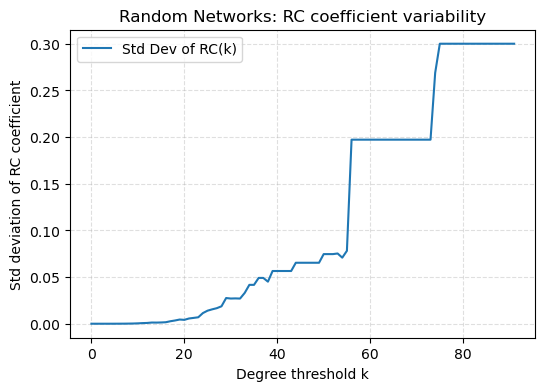

In [8]:
rc_real, rc_rand_avg, rc_rand_std, rc_norm =  rich_club(G_dir, method="config_preserving",n_rand=10,plot_rand_stats=True)

# Teacher cell
visualizing different randomization regimes

################################################
ground truth connectivity:


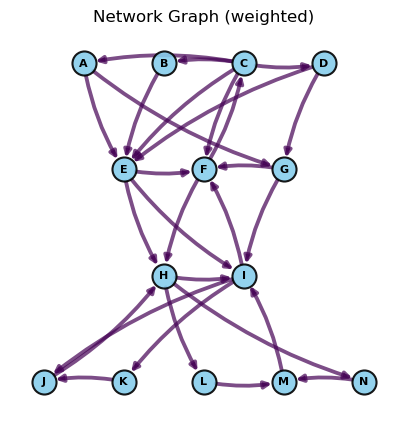

################################################
Randomized, with preserved degrees:


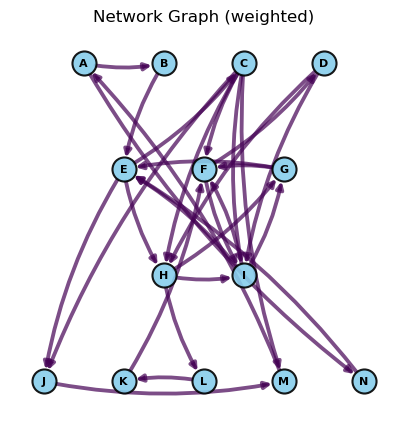

################################################
Erdos Renyi:


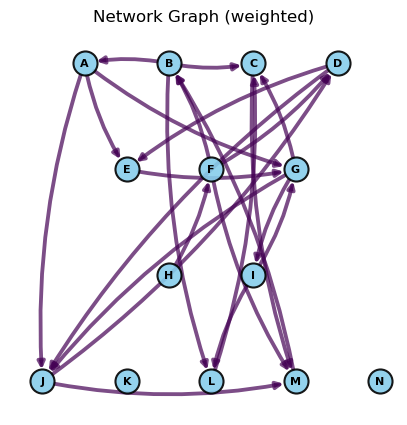

################################################
ground truth connectivity:
NETWORK STATISTICS
Number of neurons: 14
Total number of connections: 28
--------------------------------------------------------------
DEGREE STATISTICS
Average in-degree: 2.0
Average out-degree: 2.0
--------------------------------------------------------------
PATH LENGTH AND REACHABILITY
Average directed shortest path length: 2.9615384615384617
Reachability: 100.0 %
--------------------------------------------------------------
CLUSTERING AND SMALL-WORLDNESS
Average clustering coefficient: 0.37755102040816324
Random network clustering: 0.3326530612244898
Real network path length (largest component): 1.978021978021978
Random network path length: 1.954822954822955
Small-world coefficient (sigma): 1.1216579565250322
################################################
Randomized, with preserved degrees:
NETWORK STATISTICS
Number of neurons: 14
Total number of connections: 28
---------------------------------------

{'average_in_degree': np.float64(1.6428571428571428),
 'average_out_degree': np.float64(1.6428571428571428),
 'average_path_length': np.float64(2.6216216216216215),
 'reachability': 60.98901098901099,
 'clustering_coefficient': 0.17857142857142858,
 'random_clustering': np.float64(0.3316071428571429),
 'path_length_lcc': 1.9545454545454546,
 'random_path_length': np.float64(1.9196969696969695),
 'small_world_sigma': np.float64(0.5289017461689062)}

In [12]:
g_preserved = randomize_graph(G_bio,method="config_preserving",n_type="directed")
g_erdos = randomize_graph(G_bio,method="erdos_renyi",n_type="directed")

print('################################################')
print("ground truth connectivity:")
plot_network(G_bio,positions=positions)
print('################################################')
print("Randomized, with preserved degrees:")
plot_network(g_preserved,positions=positions)
print('################################################')
print("Erdos Renyi:")
plot_network(g_erdos,positions=positions)

print('################################################')
print("ground truth connectivity:")
basic_stats(G_bio)
print('################################################')
print("Randomized, with preserved degrees:")
basic_stats(g_preserved)
print('################################################')
print("Erdos Renyi:")
basic_stats(g_erdos)


# Let's see how computing the random reference netorks influences the rich club detection. 

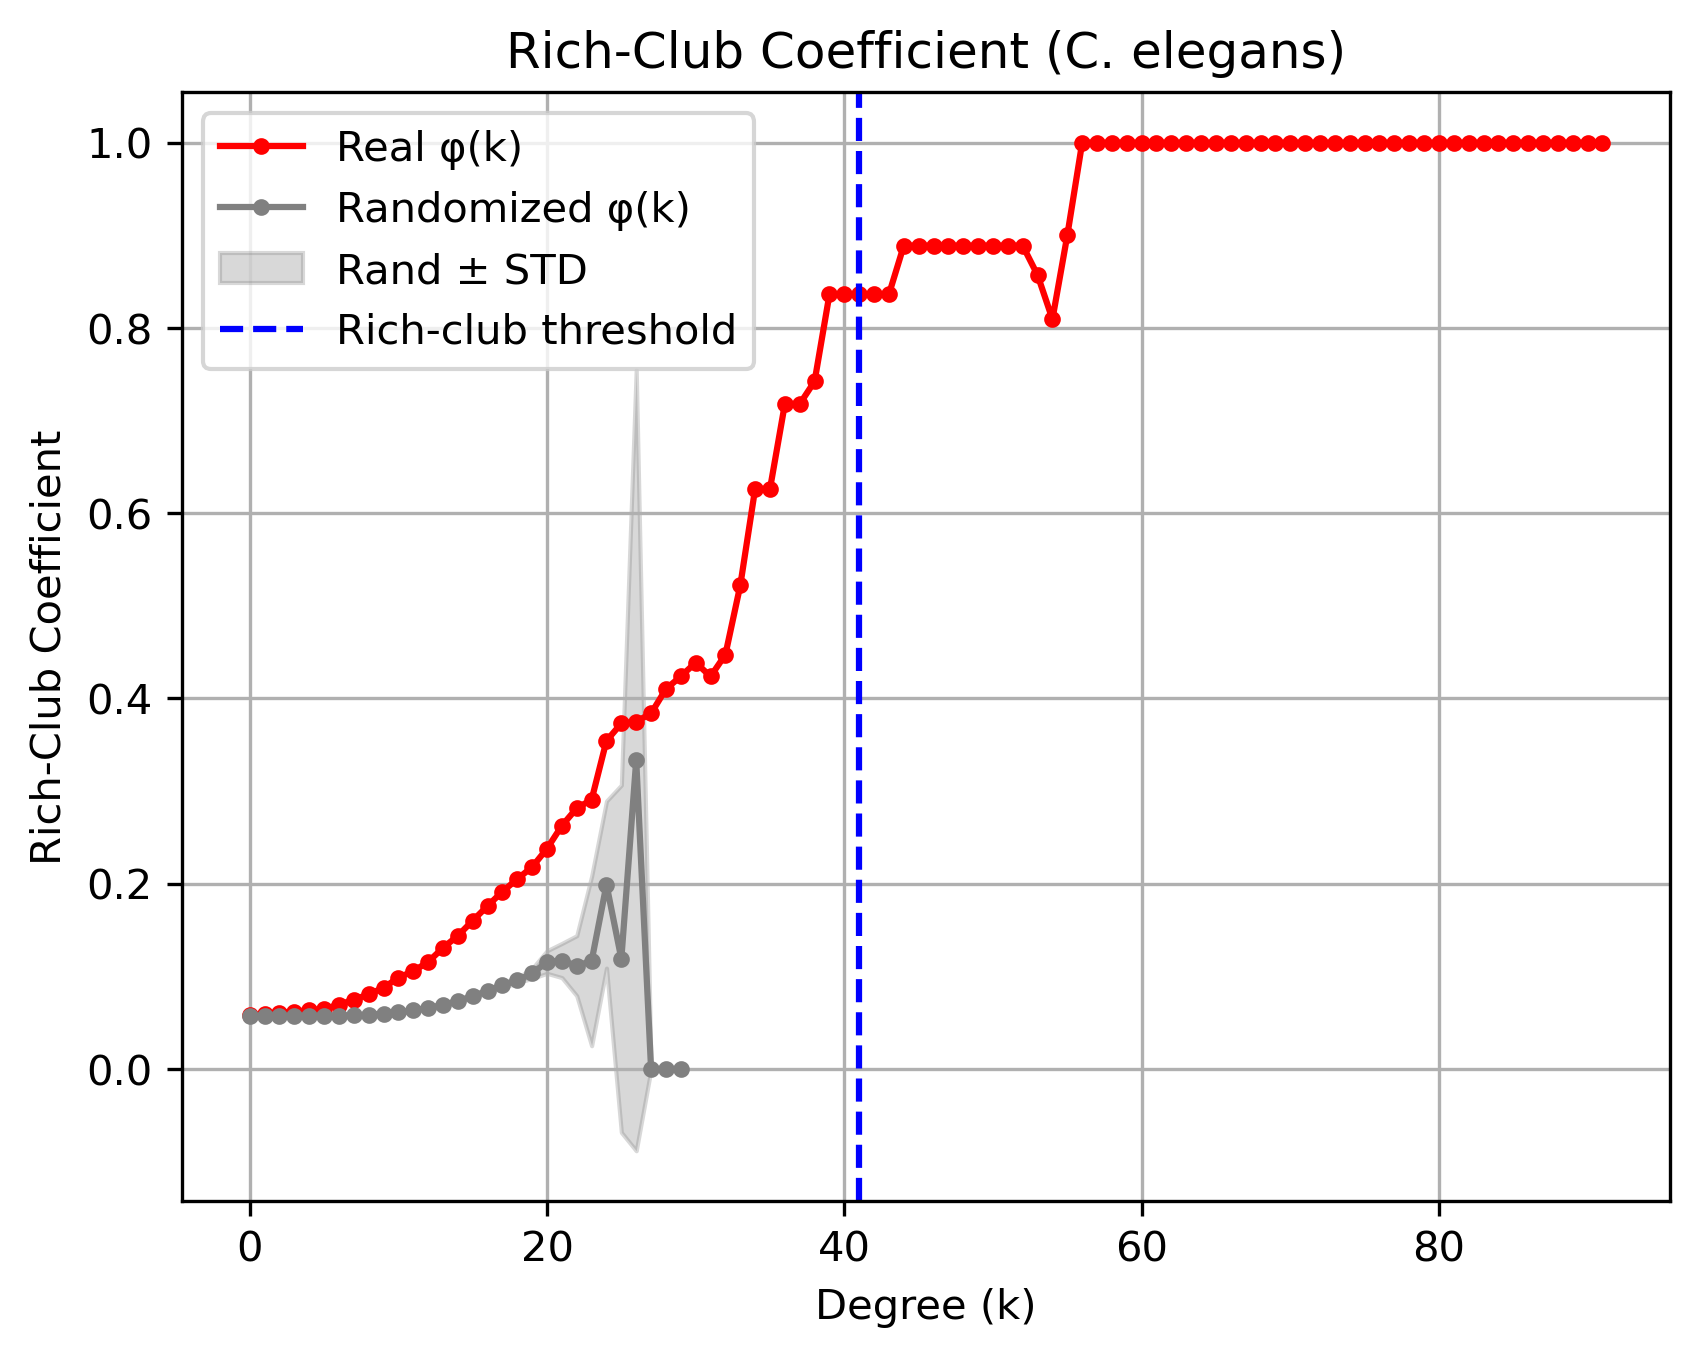

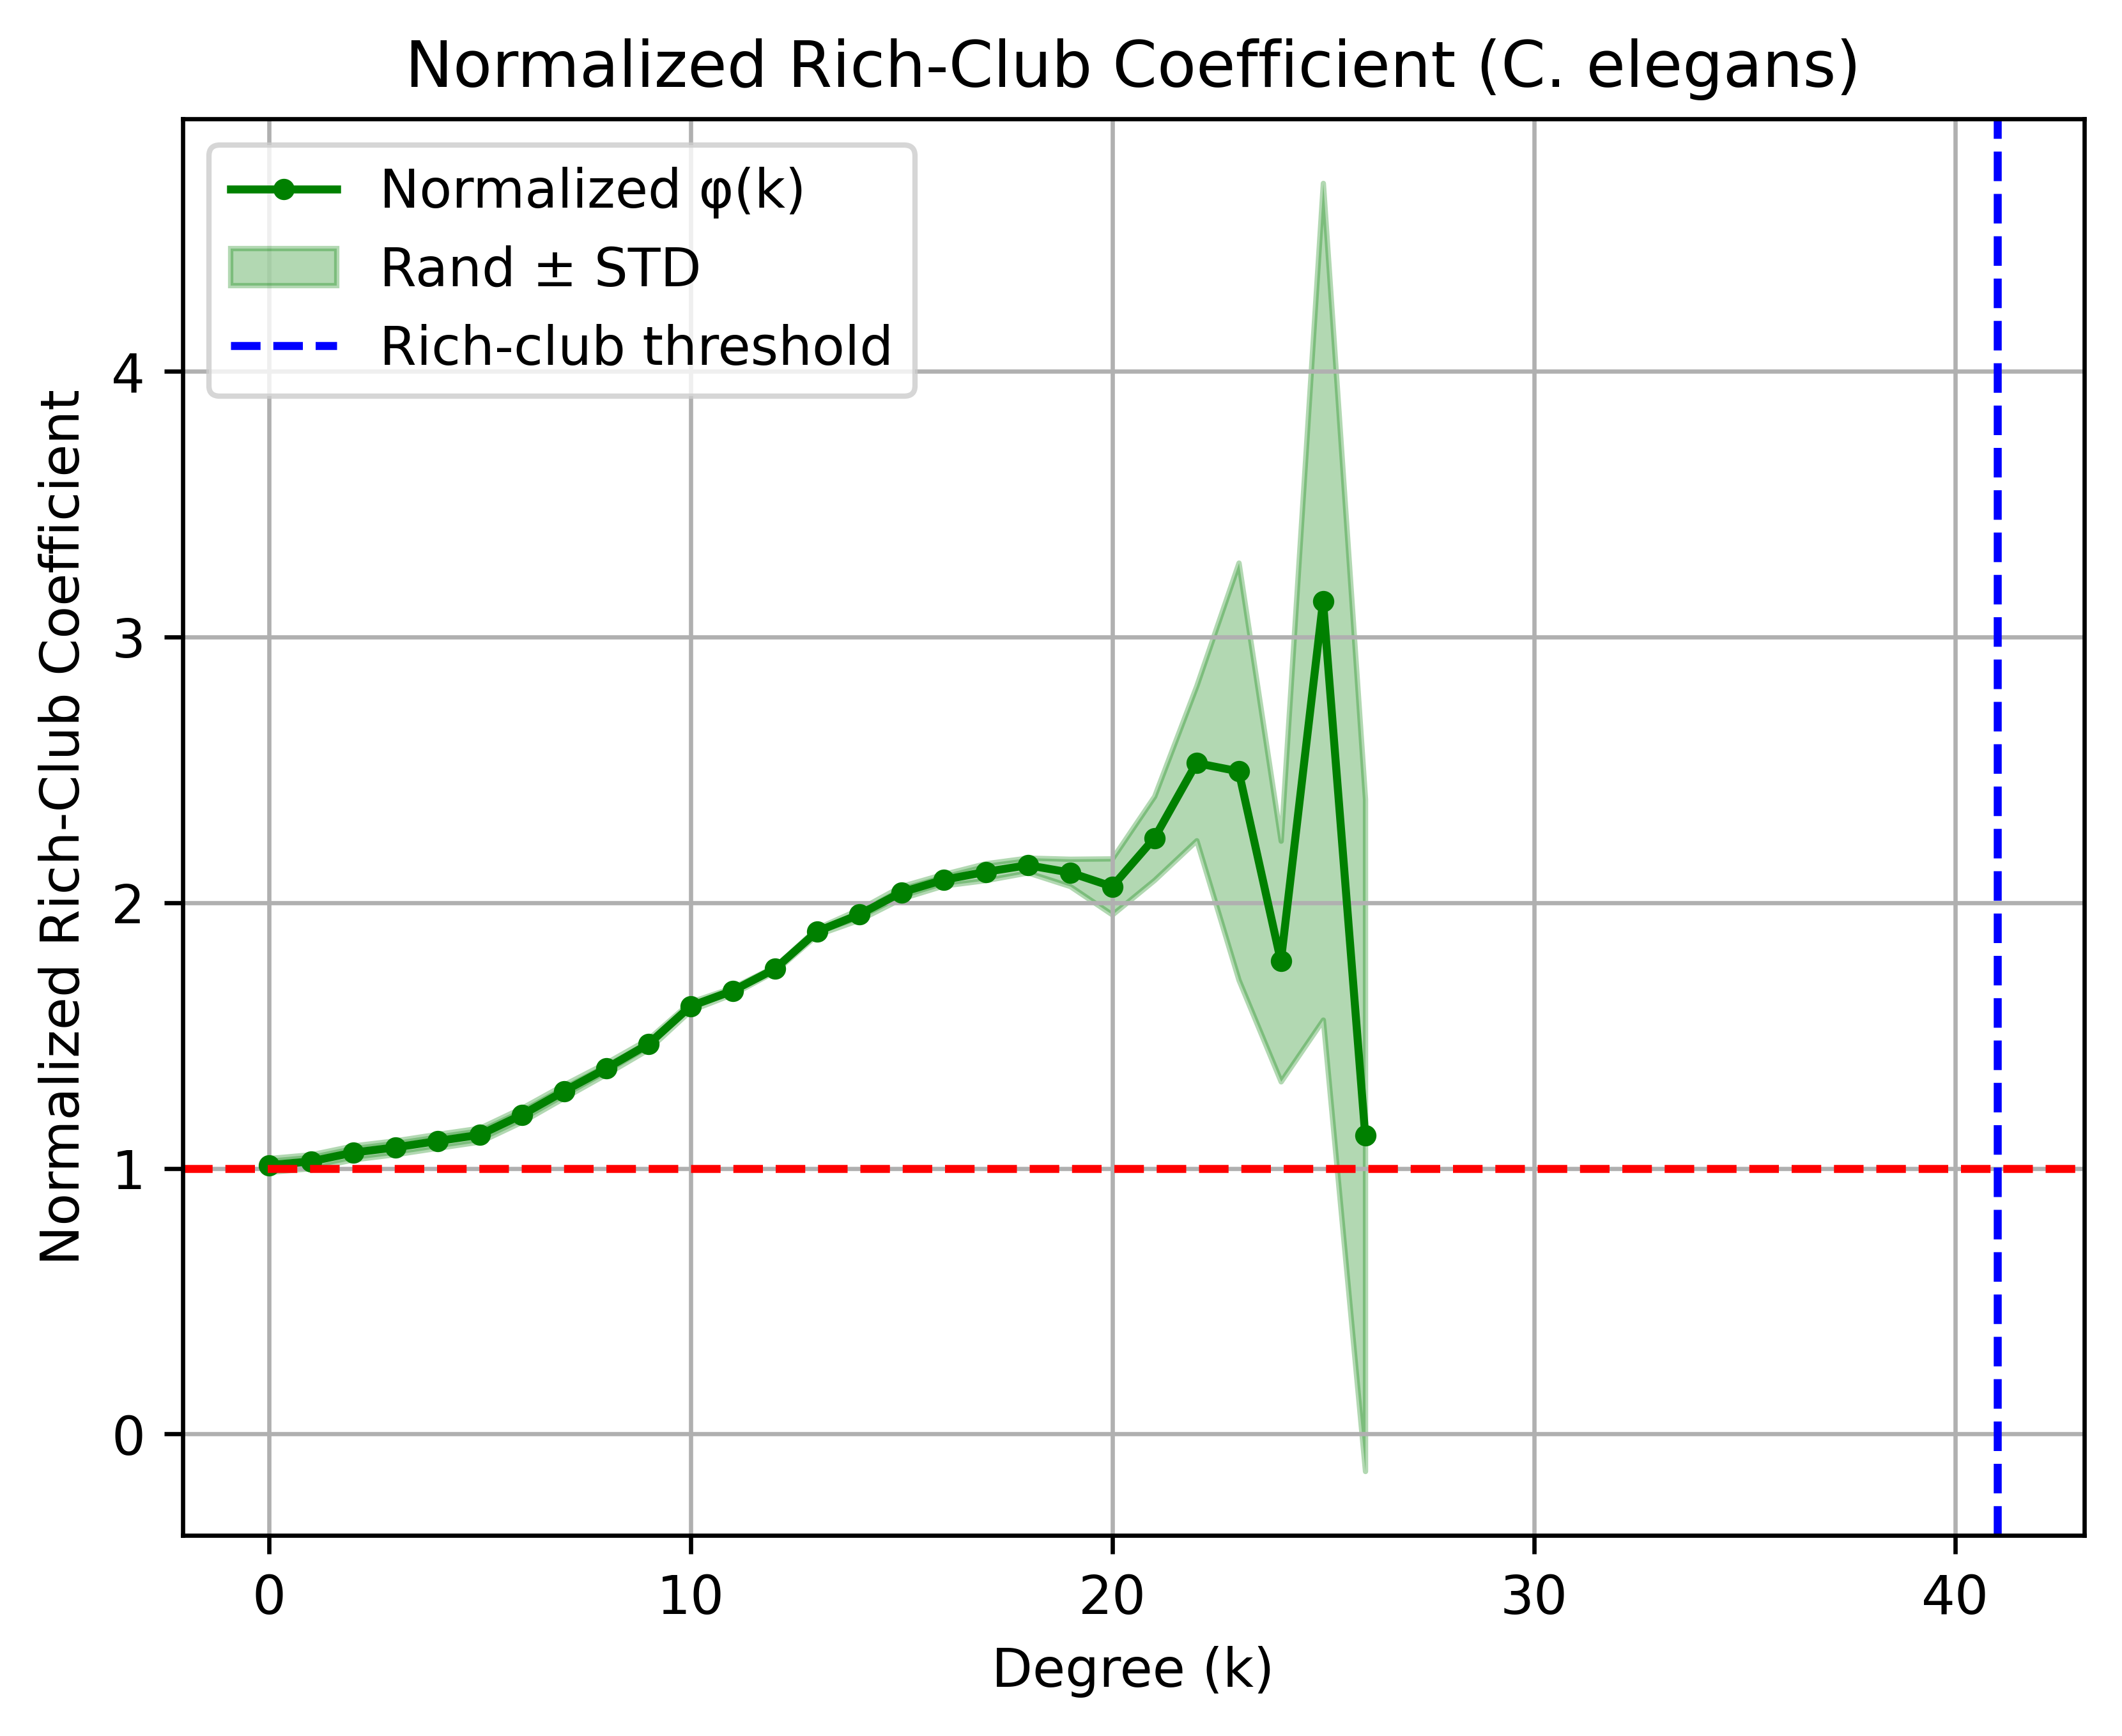

In [10]:
rc_real, rc_rand_avg, rc_rand_std, rc_norm = rich_club(G_dir, method="erdos_renyi",n_rand=10)
plot_rich_club(rc_real,rc_rand_avg,rc_rand_std,rc_norm,k_vals,k_rich)


## Let's see how these random networks diverge from the real ones: 
### We are calculating graph metrics for the real, the configuration-preserved randomized, and the Erdos-Renyi ntwrkx

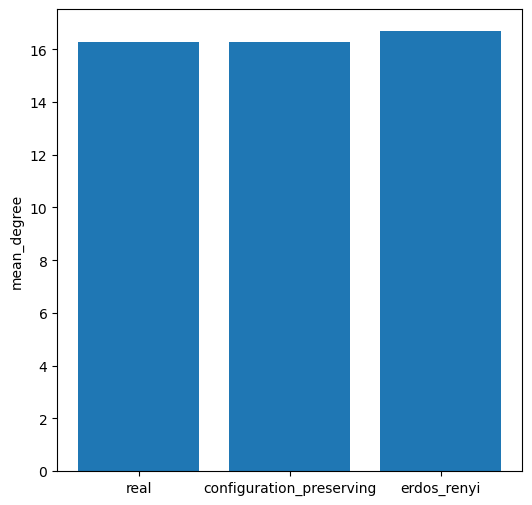

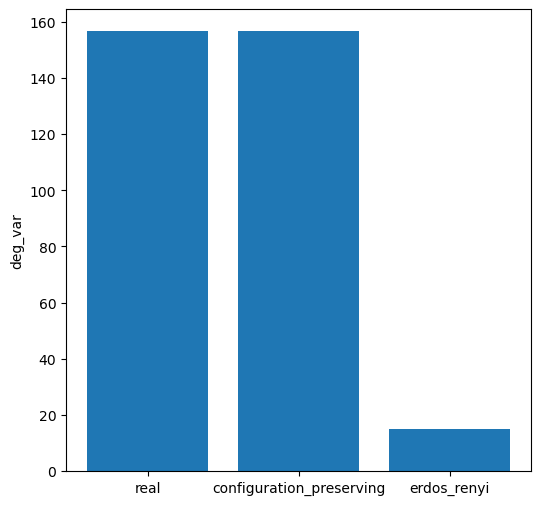

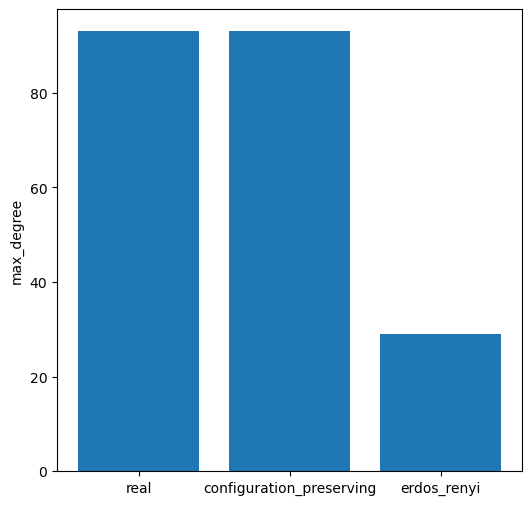

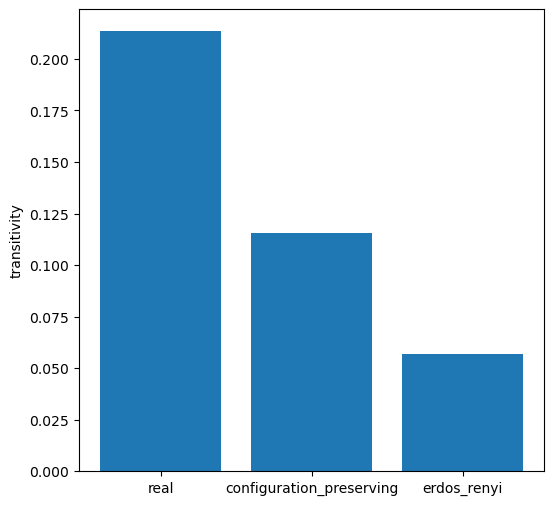

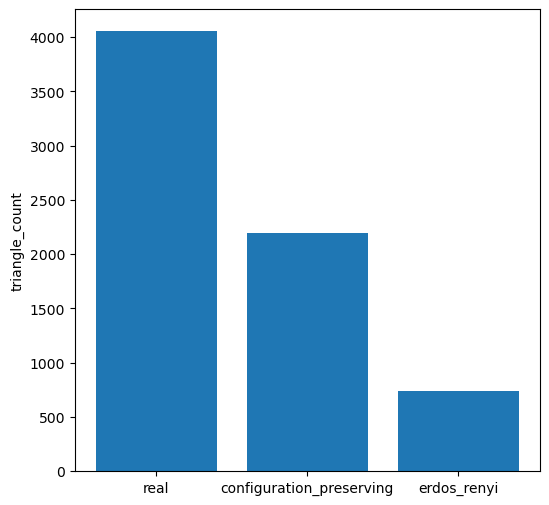

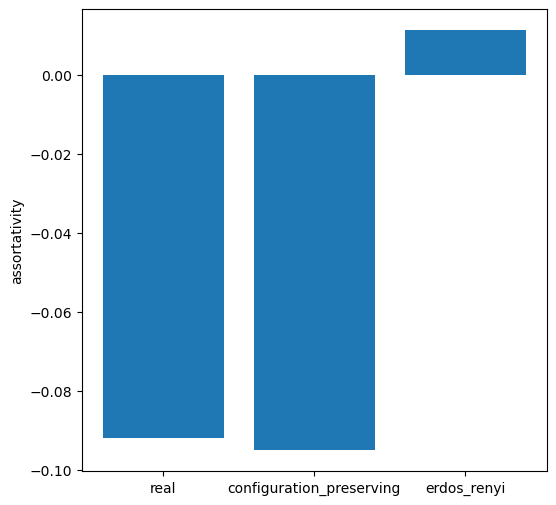

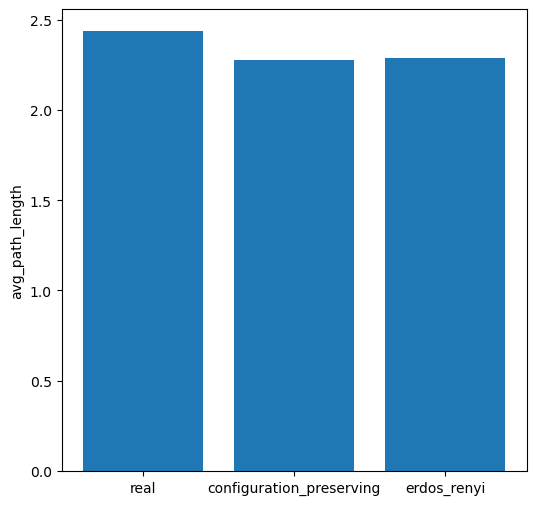

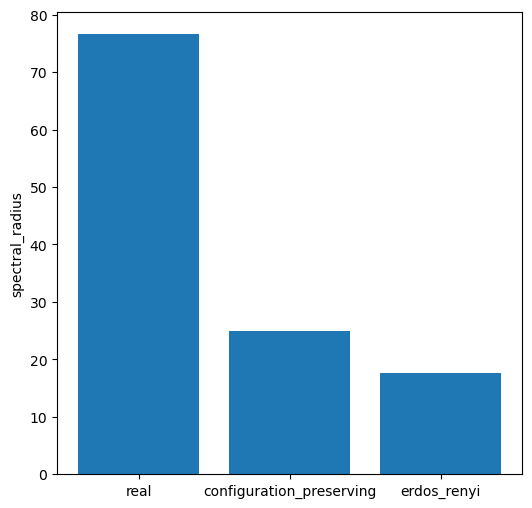

In [11]:
#Erdos-Renyi as the base of comparison ========================================

avg_degree_real = np.mean([d for n, d in G_und.degree()])
m_real = metric_set(G_und)


G_preserved = randomize_graph(G_und, method="config_preserving")
avg_degree_preserved = np.mean([d for n, d in G_preserved.degree()])
m_preserved = metric_set(G_preserved)

G_er = randomize_graph(G_und, method="erdos_renyi")
avg_degree_er = np.mean([d for n, d in G_er.degree()])
m_er = metric_set(G_er)
labels = ['real','configuration_preserving', 'erdos_renyi']

for i in m_er.keys():
    fig, ax = plt.subplots(figsize=(6,6))
    ax.set_ylabel(i)
    ax.bar(range(3),[m_real[i],m_preserved[i],m_er[i]])
    ax.set_xticks(range(3))
    ax.set_xticklabels(labels)
    plt.show()


# Let us look at the connectivity statistics of the network 
* Betweeness
* Degree
* Nodal efficiency
* Participation

In [12]:
#BETWEENNESS 
G = G_und

degree_dict = dict(G.degree()) # puts all the degrees into a dict. 
betweenness = nx.betweenness_centrality(G, normalized=True)
print(betweenness['AIAL'])
print(betweenness['AVAL'])


0.0039288383248174226
0.10182313977947362


## Participation coefficient

In [13]:
communities = list(community.greedy_modularity_communities(G))
modules = {}
for i, com in enumerate(communities):
    for node in com:
        modules[node] = i
participation = participation_coefficient(G, modules)
print(participation['AIAL'])
print(participation['AVAL'])


0.32199546485260777
0.4045368620037808


## Nodal efficiency

In [14]:
nodal_eff = nodal_efficiency(G)
print(nodal_eff['AIAL'])
print(nodal_eff['AVAL'])

0.44064748201438847
0.6546762589928058


## Determining Rich Club, Periphery, and Whole Network

In [15]:
# ======== RICH CLUB CLASSIFICATION ==========================================
#back up richclub from the paper (for comparison)
richclub_nodes_paper = ['AVDR',
 'AVAR',
 'AVBL',
 'AVBR',
 'AVDL',
 'AVEL',
 'AVAL',
 'AVER',
 'PVCL',
 'DVA',
 'PVCR']

threshold = 44
richclub_nodes = [n for n, d in degree_dict.items() if d >= threshold]
labels = {n: ("Rich club" if n in richclub_nodes else "Periphery") for n in G.nodes()} # CONSTRUCTING LABELS 

# ======== ASSEMBLE DATAFRAME =================================================
df = pd.DataFrame({
    "neuron": list(G.nodes()),
    "degree": [degree_dict[n] for n in G.nodes()],
    "betweenness": [betweenness[n] for n in G.nodes()],
    "nodal_eff": [nodal_eff[n] for n in G.nodes()],
    "participation": [participation[n] for n in G.nodes()],
    "group": [labels[n] for n in G.nodes()]  # THIS LABELS THEM EITHER as RC or PRERIPHERY
})

# Add "Whole network" group by duplicating rows
df_whole = df.copy()
df_whole["group"] = "Whole network"
df_all = pd.concat([df, df_whole], ignore_index=True)
print(df_all)


    neuron  degree  betweenness  nodal_eff  participation          group
0     ADAR      22     0.005752   0.510192       0.623967      Periphery
1     ADAL      25     0.010178   0.519784       0.652800      Periphery
2     ADFL      10     0.000564   0.410971       0.500000      Periphery
3     ASHL      20     0.004783   0.498201       0.665000      Periphery
4     AVDR      55     0.023046   0.574341       0.286942      Rich club
..     ...     ...          ...        ...            ...            ...
557  SIBVR       9     0.001263   0.435851       0.197531  Whole network
558  SIBDL       3     0.000026   0.363609       0.000000  Whole network
559   PLNL       2     0.000000   0.329736       0.000000  Whole network
560   PLNR       2     0.000000   0.334233       0.000000  Whole network
561   VD07       7     0.000258   0.366307       0.000000  Whole network

[562 rows x 6 columns]


## Plotting the coefficients for:
* Rich club
* periphery 
* whole network 

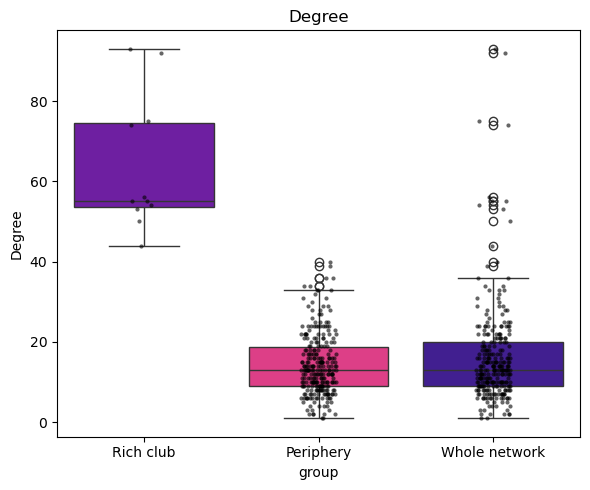

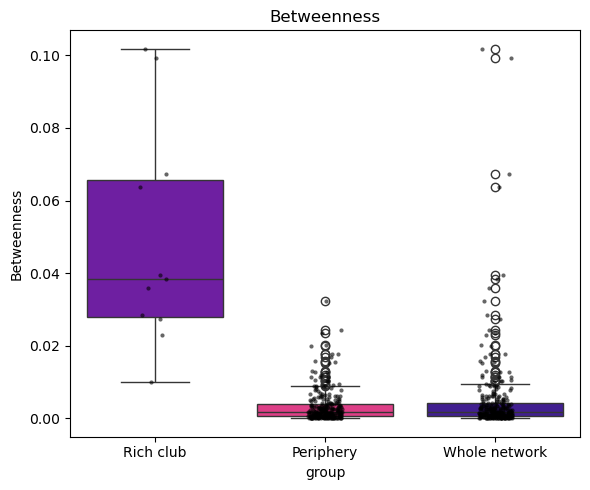

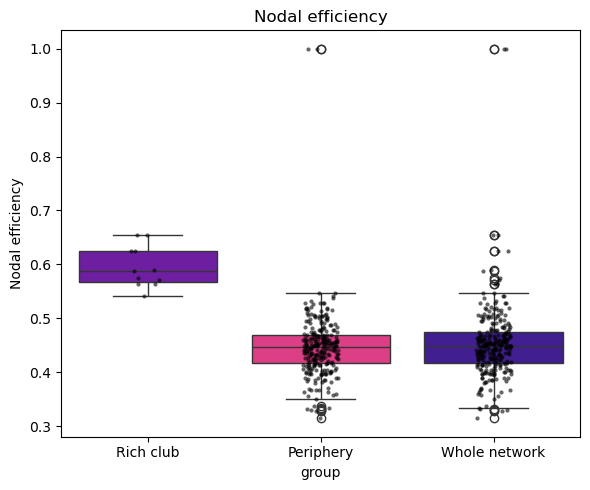

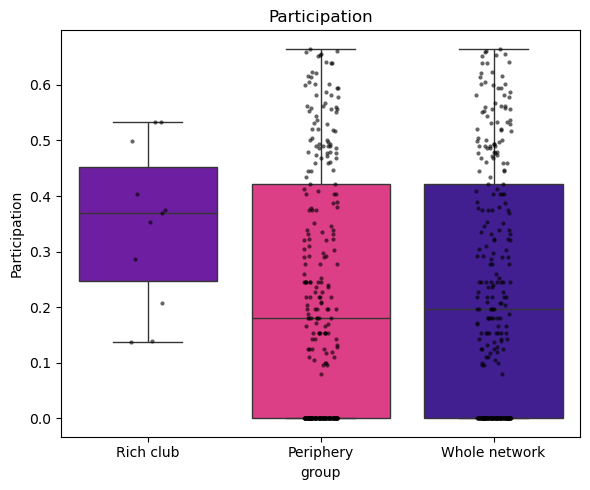

In [16]:
# ======== PLOTS ==============================================================
metrics = ["degree", "betweenness", "nodal_eff", "participation"]
labels = ["Degree","Betweenness", "Nodal efficiency", "Participation"]

for m,l in zip(metrics,labels):
    plt.figure(figsize=(6,5))
    sns.boxplot(
        data=df_all,
        x="group", y=m,
        hue="group",
        order=["Rich club", "Periphery", "Whole network"],
        palette=["#F72585", "#7209B7", "#3A0CA3"], #["red", "blue", "gray"],
        legend=False
        )
    sns.stripplot(data=df_all, x="group", y=m, order=["Rich club","Periphery","Whole network"],
                  color="k", size=3, jitter=True, alpha=0.6)
    plt.ylabel(l)
    plt.title(l)
    plt.tight_layout()
    plt.show()